# 04 · Instrumental variables and two-stage least squares

Notebooks 01–03 assumed every confounder is observed. Here the confounder `U` is **hidden**, which is
exactly the price-endogeneity problem: unobserved demand shocks move both price and sales.

```
       U (hidden)
      ↙   ↘
 Z ─► D ──► Y        W ─► D, W ─► Y   (observed control)
```

An **instrument** `Z` must satisfy:
1. **Relevance:** `Z` moves `D` (testable: first-stage F).
2. **Exclusion:** `Z` affects `Y` *only* through `D` (not testable, argued from domain knowledge).
3. **Independence:** `Z` is unrelated to `U` (not testable).

In the pricing setting, supplier cost is the textbook instrument for retail price.

**You will implement:** the Wald estimator, 2SLS with correct classical and robust standard errors,
the first-stage F statistic, and the "manual two-stage" standard-error trap.

**Library check:** `linearmodels.iv.IV2SLS`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.iv import IV2SLS

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()

sim = cs.iv_data(n=5_000, effect=1.5, instrument_strength=1.0, seed=0)
df = sim.data
n = len(df)
print(sim)

SimResult(n=5000, cols=['Z', 'W', 'D', 'Y'], truth={effect=1.5, first_stage=1})


## 1. Why OLS fails

In [2]:
Xo = np.column_stack([np.ones(n), df.D, df.W])
b_ols = np.linalg.lstsq(Xo, df.Y.to_numpy(), rcond=None)[0]
print(f"OLS coefficient on D: {b_ols[1]:.3f}   (truth {sim.truth['effect']})")

OLS coefficient on D: 2.190   (truth 1.5)


`U` raises both `D` and `Y`, so OLS attributes part of `U`'s effect to `D`.

## 2. From scratch: the Wald estimator (one instrument, no controls)

$\hat\beta_{IV} = \dfrac{\text{Cov}(Z,Y)}{\text{Cov}(Z,D)}$: the effect of `Z` on `Y` divided by the effect of `Z` on `D`.
That is "reduced form over first stage".

In [3]:
wald = np.cov(df.Z, df.Y)[0, 1] / np.cov(df.Z, df.D)[0, 1]
print(f"Wald estimate: {wald:.3f}")

Wald estimate: 1.475


## 3. From scratch: 2SLS with controls

With regressors $X=[1, D, W]$ and instruments $Z=[1, Z, W]$ (exogenous controls instrument themselves):

- Projection: $\hat X = P_Z X$, with $P_Z = Z(Z^\top Z)^{-1}Z^\top$
- $\hat\beta = (\hat X^\top X)^{-1}\hat X^\top y$
- **Residuals use the actual $X$, not $\hat X$:** $e = y - X\hat\beta$
- Classical covariance: $\hat\sigma^2(\hat X^\top \hat X)^{-1}$ with $\hat\sigma^2 = e^\top e / n$
- Robust (HC0) covariance: $(\hat X^\top\hat X)^{-1}\,\hat X^\top \text{diag}(e^2)\hat X\,(\hat X^\top\hat X)^{-1}$

In [4]:
def tsls(y, X, Z):
    Xhat = Z @ np.linalg.solve(Z.T @ Z, Z.T @ X)
    beta = np.linalg.solve(Xhat.T @ X, Xhat.T @ y)
    e = y - X @ beta
    bread = np.linalg.inv(Xhat.T @ Xhat)
    se_classical = np.sqrt(np.diag(e @ e / len(y) * bread))
    se_robust = np.sqrt(np.diag(bread @ ((Xhat * e[:, None] ** 2).T @ Xhat) @ bread))
    return beta, se_classical, se_robust


def first_stage_F(D, Z_excl, controls):
    """F-test that the excluded instruments' coefficients are 0 in the first stage."""
    n = len(D)
    Xr = np.column_stack([np.ones(n), controls])
    Xu = np.column_stack([Xr, Z_excl])
    rss = lambda X: np.sum((D - X @ np.linalg.lstsq(X, D, rcond=None)[0]) ** 2)
    q = Xu.shape[1] - Xr.shape[1]
    return ((rss(Xr) - rss(Xu)) / q) / (rss(Xu) / (n - Xu.shape[1]))


y = df.Y.to_numpy()
X = np.column_stack([np.ones(n), df.D, df.W])
Z = np.column_stack([np.ones(n), df.Z, df.W])
beta, se_c, se_r = tsls(y, X, Z)
F = first_stage_F(df.D.to_numpy(), df.Z.to_numpy(), df.W.to_numpy())
print(f"2SLS: {beta[1]:.3f} ± {1.96*se_r[1]:.3f} (robust)   first-stage F = {F:.0f}")

2SLS: 1.460 ± 0.068 (robust)   first-stage F = 2274


### The manual-two-stage trap
Running the second stage yourself (`Y ~ D_hat + W` with OLS) gives the **right coefficient** and
**wrong standard errors**, because OLS computes residuals with $\hat D$ instead of $D$.

In [5]:
D_hat = Z @ np.linalg.lstsq(Z, df.D.to_numpy(), rcond=None)[0]
X2 = np.column_stack([np.ones(n), D_hat, df.W])
b2 = np.linalg.lstsq(X2, y, rcond=None)[0]
e_wrong = y - X2 @ b2
se_wrong = np.sqrt(np.diag(e_wrong @ e_wrong / (n - 3) * np.linalg.inv(X2.T @ X2)))
print(f"manual second stage: coef {b2[1]:.4f} (same), SE {se_wrong[1]:.4f} vs correct {se_c[1]:.4f}")

manual second stage: coef 1.4599 (same), SE 0.0589 vs correct 0.0343


## 4. Library check: linearmodels
linearmodels orders parameters as `Intercept, W, D`, so reorder before comparing.
`cov_type="unadjusted"` ↔ classical, `cov_type="robust"` ↔ HC0.

In [6]:
fit_c = IV2SLS.from_formula("Y ~ 1 + W + [D ~ Z]", df).fit(cov_type="unadjusted")
fit_r = IV2SLS.from_formula("Y ~ 1 + W + [D ~ Z]", df).fit(cov_type="robust")
order = ["Intercept", "D", "W"]

np.testing.assert_allclose(beta, fit_c.params[order], rtol=1e-10)
np.testing.assert_allclose(se_c, fit_c.std_errors[order], rtol=1e-10)
np.testing.assert_allclose(se_r, fit_r.std_errors[order], rtol=1e-10)
assert abs(beta[1] - sim.truth["effect"]) < 0.1
print("✓ 2SLS coefficients, classical SE and robust SE match linearmodels")
fit_r.first_stage

✓ 2SLS coefficients, classical SE and robust SE match linearmodels


,D
R-squared,0.3730
Partial R-squared,0.3128
Shea's R-squared,0.3128
Partial F-statistic,2202.9
P-value (Partial F-stat),0.0000
Partial F-stat Distn,chi2(1)
==========================,==========
Intercept,0.0057
,(0.2892)
W,0.5087


## 5. Break it: weak instruments

As `instrument_strength` shrinks, 2SLS becomes biased toward OLS and its distribution develops
heavy tails. The old rule of thumb is first-stage F > 10; modern work (Lee et al., 2022) argues for much more.

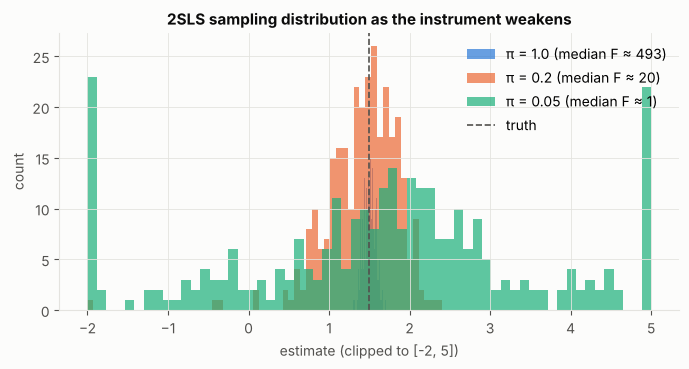

,count,mean,std,min,5%,50%,95%,max
strength,,,,,,,,
0.05,300.0,3.811,91.152,-763.207,-4.050,1.816,5.742,1376.373
0.20,300.0,1.407,0.482,-2.740,0.742,1.475,2.011,2.405
1.00,300.0,1.494,0.075,1.230,1.381,1.495,1.619,1.704


In [7]:
rows = []
for strength in (1.0, 0.2, 0.05):
    for s in range(300):
        d = cs.iv_data(n=1_000, instrument_strength=strength, seed=10_000 + s).data
        nn = len(d)
        Xs = np.column_stack([np.ones(nn), d.D, d.W])
        Zs = np.column_stack([np.ones(nn), d.Z, d.W])
        b, _, _ = tsls(d.Y.to_numpy(), Xs, Zs)
        rows.append({"strength": strength, "estimate": b[1],
                     "F": first_stage_F(d.D.to_numpy(), d.Z.to_numpy(), d.W.to_numpy())})
weak = pd.DataFrame(rows)

fig, ax = plt.subplots()
for strength, g in weak.groupby("strength", sort=False):
    ax.hist(g.estimate.clip(-2, 5), bins=60, alpha=0.7, label=f"π = {strength} (median F ≈ {g.F.median():.0f})")
truth_line(ax, 1.5)
ax.set(title="2SLS sampling distribution as the instrument weakens", xlabel="estimate (clipped to [-2, 5])", ylabel="count")
ax.legend()
plt.show()
weak.groupby("strength").estimate.describe(percentiles=[0.05, 0.5, 0.95]).round(3)

## 6. Break it: exclusion violation
Now `Z` also affects `Y` directly. The first stage still looks strong, yet the estimate is wrong.
No statistic in this dataset can detect the problem.

In [8]:
for viol in (0.0, 0.3, 1.0):
    d = cs.iv_data(n=50_000, exclusion_violation=viol, seed=5).data
    nn = len(d)
    b, _, _ = tsls(d.Y.to_numpy(), np.column_stack([np.ones(nn), d.D, d.W]), np.column_stack([np.ones(nn), d.Z, d.W]))
    print(f"exclusion violation {viol:.1f}: 2SLS = {b[1]:.3f}  (truth 1.5)")

exclusion violation 0.0: 2SLS = 1.509  (truth 1.5)
exclusion violation 0.3: 2SLS = 1.808  (truth 1.5)
exclusion violation 1.0: 2SLS = 2.506  (truth 1.5)


**Exercises**
1. Add a second instrument and implement the Sargan/Hansen over-identification test. Check it against `fit.sargan`.
2. Implement the Anderson–Rubin confidence set, which stays valid under weak instruments.
3. Use `cs.retail_pricing()`: instrument `log(price_1)` with `cost_1` and estimate the own-price elasticity of `purch_1`.
   Compare with OLS. Prices rise with unobserved demand here, so which direction should OLS be biased?